In [ ]:
# Import Library dan Dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file = '/content/drive/MyDrive/SEMESTER 4/BIG DATA/UAS/dfTransjakarta_FIX.xlsx'
tj = pd.read_excel(file)

In [2]:
# Mencetak 5 baris pertama
tj.head()

,transID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,tapInStopsName,tapInTime,tapOutStopsName,tapOutTime,payAmount
0,EIIW227B8L34VB,emoney,Bajragin Usada,M,2008,5,Matraman Baru - Ancol,Pal Putih,2023-04-03 05:21:00,Tegalan,2023-04-03 06:00:00,3500.0
1,LGXO740D2N47GZ,dki,Gandi Widodo,F,1997,6C,Stasiun Tebet - Karet via Patra Kuningan,Kemenkes 2,2023-04-03 05:42:00,Sampoerna Strategic,2023-04-03 06:40:00,3500.0
2,DJWR385V2U57TO,dki,Emong Wastuti,F,1992,R1A,Pantai Maju - Kota,Gg. Kunir II,2023-04-03 05:59:00,Simpang Kunir Kemukus,2023-04-03 06:50:00,3500.0
3,JTUZ800U7C86EH,flazz,Surya Wacana,F,1978,11D,Pulo Gebang - Pulo Gadung 2 via PIK,Taman Elok 1,2023-04-03 05:44:00,Raya Penggilingan,2023-04-03 06:28:00,3500.0
4,VMLO535V7F95NJ,flazz,Embuh Mardhiyah,M,1982,12,Tanjung Priok - Pluit,Sunter Boulevard Barat,2023-04-03 06:17:00,Kali Besar Barat,2023-04-03 06:57:00,3500.0


In [3]:
# Mengecek nama kolom
tj.columns

Index(['transID', 'payCardBank', 'payCardName', 'payCardSex',
       'payCardBirthDate', 'corridorID', 'corridorName', 'tapInStopsName',
       'tapInTime', 'tapOutStopsName', 'tapOutTime', 'payAmount'],
      dtype='object')

Terdapat 12 kolom yang ada di dataset.
*   transID: ID transaksi dari setiap pelanggan > primary key, supaya tidak ada data duplikat.
*   payCardBank: jenis kartu yang digunakan pelanggan untuk tap in dan tap out.
*   payCardName: nama pada kartu yang digunakan pelanggan.
*   payCardSex: jenis kelamin pelanggan.
*   payCardBirthDate: tahun kelahiran pelanggan.
*   corridorID: kode rute Transjakarta tertentu, misalnya 1 untuk Blok M - Kota, 1A untuk Balaikota - Pantai Maju.
*   corridorName: nama rute Transjakarta, misalnya Kalideres - Gelora Bung Karno, Lebak Bulus - Pasar Baru.
*   tapInStopsName: nama halte tempat pelanggan melakukan tap in kartu.
*   tapInTime: waktu pelanggan melakukan tap in kartu.
*   tapOutStopsName: nama halte tempat pelanggan melakukan tap out kartu.
*   tapOutTime: waktu pelanggan melakukan tap out kartu.
*   payAmount: tarif yang harus dibayarkan pelanggan.

In [4]:
# Mengganti nama kolom payCardName, payCardSex, dan payCardBirthDate agar mudah dicari
tj.rename(index=str, columns={"payCardName":"name", "payCardSex":"gender", "payCardBirthDate":"birthDate"}, inplace=True)

tj.columns

Index(['transID', 'payCardBank', 'name', 'gender', 'birthDate', 'corridorID',
       'corridorName', 'tapInStopsName', 'tapInTime', 'tapOutStopsName',
       'tapOutTime', 'payAmount'],
      dtype='object')

In [5]:
# Mencari berapa banyak data yang duplikat
duplicatesNum = tj.duplicated().sum()
print("Terdapat %d baris duplikat"% (duplicatesNum))

Terdapat 0 baris duplikat


In [6]:
# Menampilkan missing data and mengurutkan dalam urutan secara ascending (naik)
missingDataSummary = tj.isna().sum()

# Menghitung persentase dari missing data
missingDataPercentage = (tj.isnull().sum()/tj.shape[0])

# Menggabungkan missingDataSummary dan missingDataPercentage
missingData = pd.concat([missingDataSummary,
                         missingDataPercentage], axis=1, keys=['Missing', 'Percentage'])
missingData.sort_values(ascending=False, by='Missing')

,Missing,Percentage
corridorName,1930,0.050923
tapOutStopsName,1344,0.035462
tapOutTime,1344,0.035462
corridorID,1257,0.033166
payAmount,1007,0.026570
name,0,0.000000
payCardBank,0,0.000000
transID,0,0.000000
gender,0,0.000000
birthDate,0,0.000000


In [7]:
# Menghapus baris yang tidak memiliki nilai di salah 1 kolom yang terdapat missing values
tj.dropna(subset=['tapOutStopsName', 'tapOutTime', 'payAmount', 'corridorName', 'corridorID'], inplace=True)

In [8]:
# Mengecek apakah masih ada missing values
missingDataSummary = tj.isna().sum()
missingDataPercentage = (tj.isnull().sum()/tj.shape[0])

missingData = pd.concat([missingDataSummary,
                         missingDataPercentage], axis=1, keys=['Missing', 'Percentage'])
missingData.sort_values(ascending=False, by='Missing')

,Missing,Percentage
transID,0,0.0
payCardBank,0,0.0
name,0,0.0
gender,0,0.0
birthDate,0,0.0
corridorID,0,0.0
corridorName,0,0.0
tapInStopsName,0,0.0
tapInTime,0,0.0
tapOutStopsName,0,0.0


In [9]:
# Menyimpan data yang sudah bersih menjadi file excel baru
tj.to_excel('dfTransjakarta_Clean.xlsx', index=False)

Dataset yang telah dibersihkan akan dianalisis untuk melihat pola persebaran dan pergerakan penumpang Transjakarta. Untuk itu, digunakan algoritma K-Means Clustering guna mengelompokkan para penumpang ke dalam beberapa cluster berdasarkan karakteristik tertentu.

In [10]:
# Mengambil kolom yang diperlukan untuk clustering dan membuat salinan tabel baru
tj_clustering = pd.DataFrame()

# Mentransformasi data
tj_clustering['Time'] = pd.to_datetime(tj['tapInTime']).dt.hour
tj_clustering['Age'] = 2026 - tj['birthDate']
tj_clustering['Gender'] = tj['gender'].map({'M': 0, 'F': 1})
tj_clustering['corridorID'] = tj['corridorID']

In [11]:
print(tj_clustering.head())

   Time  Age  Gender corridorID
0     5   18       0          5
1     5   29       1         6C
2     5   34       1        R1A
3     5   48       1        11D
4     6   44       0         12


In [12]:
# Proses Clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [13]:
# Membuat variabel baru untuk K-Means
k = tj_clustering[['Time', 'Age', 'Gender']]

# Menyamakan skala data
scaler = MinMaxScaler()
k_scaled = scaler.fit_transform(k)

# Menjalankan K-Means
kmeans = KMeans(n_clusters = 3, random_state = 42)
tj_clustering['Cluster'] = kmeans.fit_predict(k_scaled)

# Menampilkan hasilnya
print(tj_clustering.head())

   Time  Age  Gender corridorID  Cluster
0     5   18       0          5        0
1     5   29       1         6C        1
2     5   34       1        R1A        1
3     5   48       1        11D        1
4     6   44       0         12        0


Data akan dikelompokkan ke dalam 3 cluster.
*   Cluster 0 adalah kelompok pekerja laki-laki yang berangkat pada pagi hari.
*   Cluster 1 adalah kelompok perempuan yang melakukan perjalanan pulang pergi (PP).
*   Cluster 2 adalah kelompok pekerja laki-laki yang pulang kerja pada sore hari.

In [14]:
# Menampilkan rata-rata setiap kolom berdasarkan cluster
cluster_profile = tj_clustering.groupby('Cluster')[['Time', 'Age', 'Gender']].mean()
print(cluster_profile)

              Time        Age  Gender
Cluster                              
0         6.934289  39.009682     0.0
1        12.573203  33.010024     1.0
2        17.833040  38.986422     0.0


In [15]:
# Melihat persebaran cluster di setiap koridor
print(pd.crosstab(tj_clustering['corridorID'], tj_clustering['Cluster']))

Cluster       0    1    2
corridorID               
1            95   36   91
2            75  114   79
3             4  114    5
4            16  151   20
5            94   51   93
...         ...  ...  ...
S21         130  122  119
S22          63    9   59
S31          19   95   26
T11          21  211   19
T21          57   57   59

[216 rows x 3 columns]


In [16]:
# Mengurutkan koridor dengan cluster terbanyak

tabel_cross = pd.crosstab(tj_clustering['corridorID'], tj_clustering['Cluster'])

print("5 Koridor Terpadat Pada Cluster 0")
print(tabel_cross[0].sort_values(ascending=False).head(5))

print("5 Koridor Terpadat Pada Cluster 1")
print(tabel_cross[1].sort_values(ascending=False).head(5))

print("5 Koridor Terpadat Pada Cluster 2")
print(tabel_cross[2].sort_values(ascending=False).head(5))

5 Koridor Terpadat Pada Cluster 0
corridorID
S21       130
11Q       116
1T        110
JIS3      105
JAK.11     97
Name: 0, dtype: int64
5 Koridor Terpadat Pada Cluster 1
corridorID
T11        211
9D         210
2E         205
JAK.112    195
JAK.36     187
Name: 1, dtype: int64
5 Koridor Terpadat Pada Cluster 2
corridorID
11Q       122
S21       119
1T        110
JIS3      100
JAK.11     96
Name: 2, dtype: int64


Proses mencari koridor terpadat dari setiap cluster dilakukan untuk melihat apakah perlu adanya penambahan koridor, terutama pada jam-jam sibuk seperti jam pergi atau pulang kerja. Selain itu, dari proses ini terlihat bahwa cluster 0 dan 2 (pekerja laki-laki) mendominasi koridor utama seperti S21 dan 11Q, sedangkan cluster 1 (penumpang perempuan yang PP) lebih menggunakan rute pengumpan dan Mikrotrans.

Untuk menyajikan data dari setiap cluster (melihat persebaran penumpang), maka digunakan grafik histrogram dan poligon untuk melihat pergerakan penumpang yang menggunakan layanan Transjakarta.

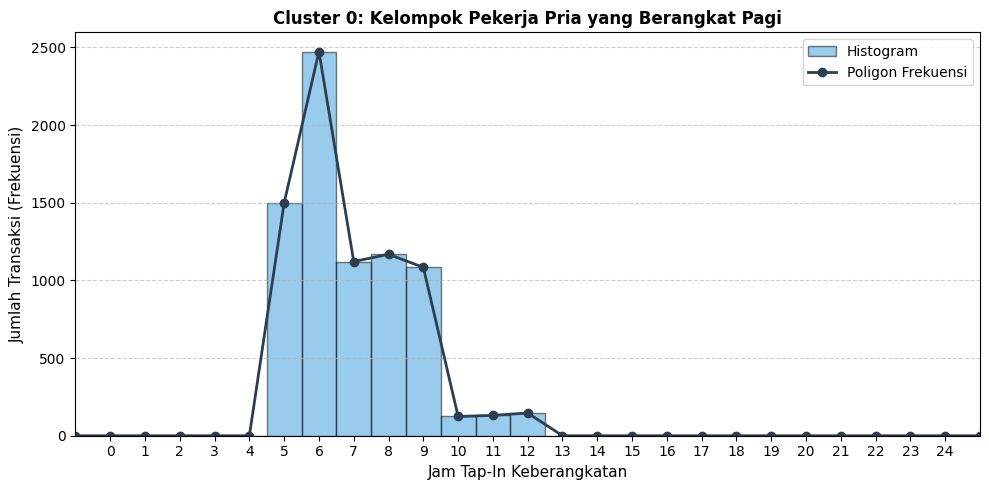

In [17]:
# Grafik untuk Cluster 0
cluster_0 = tj_clustering[tj_clustering['Cluster'] == 0]['Time']
bins = np.arange(-0.5, 25.5, 1)

# Hitung komponen Poligon Frekuensi
counts, bin_edges = np.histogram(cluster_0, bins=bins)
bin_midpoints = np.arange(0, 25)
poly_x = np.concatenate([[bin_midpoints[0] - 1], bin_midpoints, [bin_midpoints[-1] + 1]])
poly_y = np.concatenate([[0], counts, [0]])

# Plotting
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cluster_0, bins=bins, alpha=0.5, color='#3498db', edgecolor='black', label='Histogram')
ax.plot(poly_x, poly_y, color='#2c3e50', marker='o', linewidth=2, label='Poligon Frekuensi')

# Label dan Judul
ax.set_title('Cluster 0: Kelompok Pekerja Pria yang Berangkat Pagi', fontsize=12, fontweight='bold')
ax.set_xlabel('Jam Tap-In Keberangkatan', fontsize=11)
ax.set_ylabel('Jumlah Transaksi (Frekuensi)', fontsize=11)
ax.set_xticks(range(0, 25))
ax.set_xlim(-1, 25)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('Grafik_Cluster0.png')
plt.show()

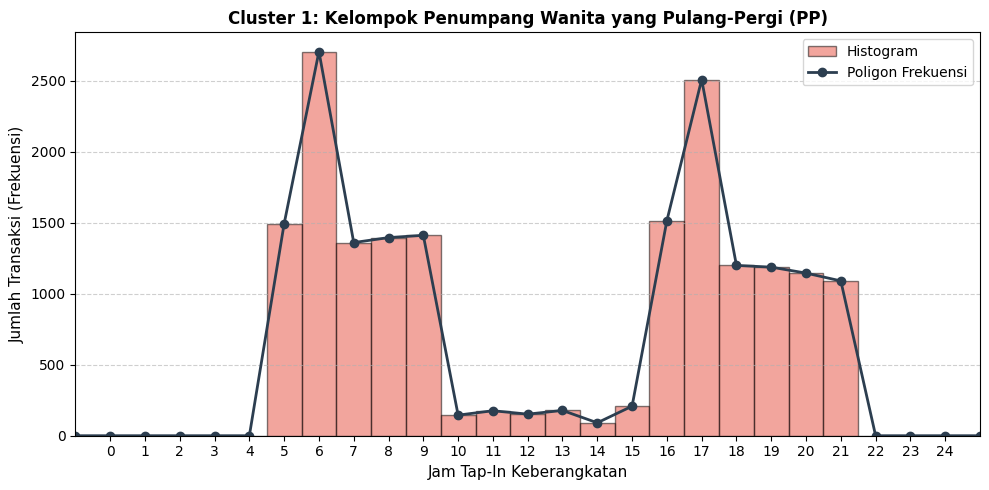

In [18]:
# Grafik untuk Cluster 1
cluster_1 = tj_clustering[tj_clustering['Cluster'] == 1]['Time']
bins = np.arange(-0.5, 25.5, 1)

# Hitung komponen Poligon Frekuensi
counts, bin_edges = np.histogram(cluster_1, bins=bins)
bin_midpoints = np.arange(0, 25)
poly_x = np.concatenate([[bin_midpoints[0] - 1], bin_midpoints, [bin_midpoints[-1] + 1]])
poly_y = np.concatenate([[0], counts, [0]])

# Plotting
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cluster_1, bins=bins, alpha=0.5, color='#e74c3c', edgecolor='black', label='Histogram')
ax.plot(poly_x, poly_y, color='#2c3e50', marker='o', linewidth=2, label='Poligon Frekuensi')

# Label dan Judul
ax.set_title('Cluster 1: Kelompok Penumpang Wanita yang Pulang-Pergi (PP)', fontsize=12, fontweight='bold')
ax.set_xlabel('Jam Tap-In Keberangkatan', fontsize=11)
ax.set_ylabel('Jumlah Transaksi (Frekuensi)', fontsize=11)
ax.set_xticks(range(0, 25))
ax.set_xlim(-1, 25)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('Grafik_Cluster1.png')
plt.show()

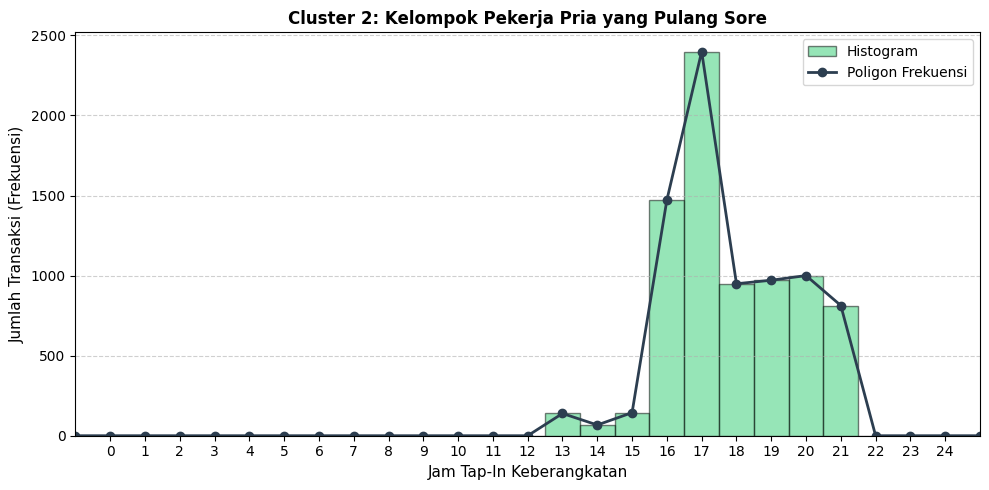

In [19]:
# Grafik untuk Cluster 2
cluster_2 = tj_clustering[tj_clustering['Cluster'] == 2]['Time']
bins = np.arange(-0.5, 25.5, 1)

# Hitung komponen Poligon Frekuensi
counts, bin_edges = np.histogram(cluster_2, bins=bins)
bin_midpoints = np.arange(0, 25)
poly_x = np.concatenate([[bin_midpoints[0] - 1], bin_midpoints, [bin_midpoints[-1] + 1]])
poly_y = np.concatenate([[0], counts, [0]])

# Plotting
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cluster_2, bins=bins, alpha=0.5, color='#2ecc71', edgecolor='black', label='Histogram')
ax.plot(poly_x, poly_y, color='#2c3e50', marker='o', linewidth=2, label='Poligon Frekuensi')

# Label dan Judul
ax.set_title('Cluster 2: Kelompok Pekerja Pria yang Pulang Sore', fontsize=12, fontweight='bold')
ax.set_xlabel('Jam Tap-In Keberangkatan', fontsize=11)
ax.set_ylabel('Jumlah Transaksi (Frekuensi)', fontsize=11)
ax.set_xticks(range(0, 25))
ax.set_xlim(-1, 25)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('Grafik_Cluster2.png')
plt.show()

In [20]:
# Melihat transaksi terbanyak di setiap cluster (MODUS)
for cluster_id in [0, 1, 2]:
    modus_jam = tj_clustering[tj_clustering['Cluster'] == cluster_id]['Time'].mode()[0]
    print("Cluster {cluster_id} memiliki transaksi terbanyak pada jam {modus_jam}.00 WIB")

Cluster {cluster_id} memiliki transaksi terbanyak pada jam {modus_jam}.00 WIB
Cluster {cluster_id} memiliki transaksi terbanyak pada jam {modus_jam}.00 WIB
Cluster {cluster_id} memiliki transaksi terbanyak pada jam {modus_jam}.00 WIB
